In [1]:
import pandas as pd
import numpy as np

In [2]:
reader=pd.read_csv(r"C:\Users\Lakshin Khurana\Downloads\bollywood.csv")

In [3]:
len(reader)

149

In [4]:
reader

,SlNo,Release Date,MovieName,ReleaseTime,Genre,Budget,BoxOfficeCollection,YoutubeViews,YoutubeLikes,YoutubeDislikes
0,1,18-Apr-14,2 States,LW,Romance,36,104.00,8576361,26622,2527
1,2,4-Jan-13,Table No. 21,N,Thriller,10,12.00,1087320,1129,137
2,3,18-Jul-14,Amit Sahni Ki List,N,Comedy,10,4.00,572336,586,54
3,4,4-Jan-13,Rajdhani Express,N,Drama,7,0.35,42626,86,19
4,5,4-Jul-14,Bobby Jasoos,N,Comedy,18,10.80,3113427,4512,1224
...,...,...,...,...,...,...,...,...,...,...
144,145,27-Feb-15,Dum Laga Ke Haisha,N,Comedy,15,30.00,3250917,8185,615
145,146,13-Mar-15,NH10,N,Thriller,13,32.10,5592977,15464,1513
146,147,20-Mar-15,Dilliwali Zaalim Girlfriend,N,Comedy,32,12.00,2316047,4289,807
147,148,20-Mar-15,Hunterrr,N,Comedy,5,11.89,4674795,3706,762


In [5]:
reader.value_counts("Genre",ascending=False)

Genre
Comedy       36
 Drama       35
Thriller     26
Romance      25
Action       21
Action        3
Thriller      3
Name: count, dtype: int64

In [6]:
reader.value_counts("Genre").idxmax(0)

'Comedy'

In [7]:
reader.value_counts("ReleaseTime","Genre")

ReleaseTime
N     0.664430
HS    0.120805
FS    0.114094
LW    0.100671
Name: proportion, dtype: float64

In [8]:
cross_table=pd.crosstab(reader["Genre"],reader["ReleaseTime"])

In [9]:
cross_table

ReleaseTime,FS,HS,LW,N
Genre,,,,
Drama,4,6,1,24
Action,3,3,3,12
Action,0,0,0,3
Comedy,3,5,5,23
Romance,3,3,4,15
Thriller,4,1,1,20
Thriller,0,0,1,2


In [10]:
pivot_table=pd.pivot_table(data=reader,index="Genre",columns="ReleaseTime", values="Budget")

In [11]:
pivot_table

ReleaseTime,FS,HS,LW,N
Genre,,,,
Drama,23.750000,20.833333,125.000000,20.916667
Action,92.666667,69.333333,62.333333,52.916667
Action,NaN,NaN,NaN,19.666667
Comedy,31.000000,20.400000,40.000000,22.391304
Romance,24.666667,22.000000,23.750000,26.266667
Thriller,37.750000,16.000000,29.000000,17.900000
Thriller,NaN,NaN,60.000000,10.000000


In [12]:
reader.value_counts("Release Date")


Release Date
9-May-14     5
18-Jan-13    3
15-Mar-13    3
25-Apr-14    3
26-Jul-13    3
            ..
23-Jan-15    1
23-Aug-13    1
22-Nov-13    1
1-Mar-13     1
1-Feb-13     1
Name: count, Length: 102, dtype: int64

In [14]:
reader['Release Date'] = pd.to_datetime(reader['Release Date'], format='%d-%b-%y')
reader['Month'] = reader['Release Date'].dt.month
month_release_count = reader['Month'].value_counts().idxmax()
month_release_count

1

In [15]:
high_budget = reader[reader['Budget'] >= 25]
month_high_budget_release = high_budget['Month'].value_counts().idxmax()
month_high_budget_release

2

In [16]:
reader['ROI'] = (reader['BoxOfficeCollection'] - reader['Budget']) / reader['Budget']
top_10_roi = reader[['MovieName', 'ROI']].sort_values(by='ROI', ascending=False).head(10)
top_10_roi


,MovieName,ROI
64,Aashiqui 2,8.166667
89,PK,7.647059
132,Grand Masti,7.514286
135,The Lunchbox,7.500000
87,Fukrey,6.240000
58,Mary Kom,5.933333
128,Shahid,5.666667
37,Humpty Sharma Ki Dulhania,5.500000
101,Bhaag Milkha Bhaag,4.466667
115,Chennai Express,4.266667


In [17]:
avg_roi_by_time = reader.groupby('ReleaseTime')['ROI'].mean()
avg_roi_by_time


ReleaseTime
FS    0.973853
HS    0.850867
LW    1.127205
N     0.657722
Name: ROI, dtype: float64

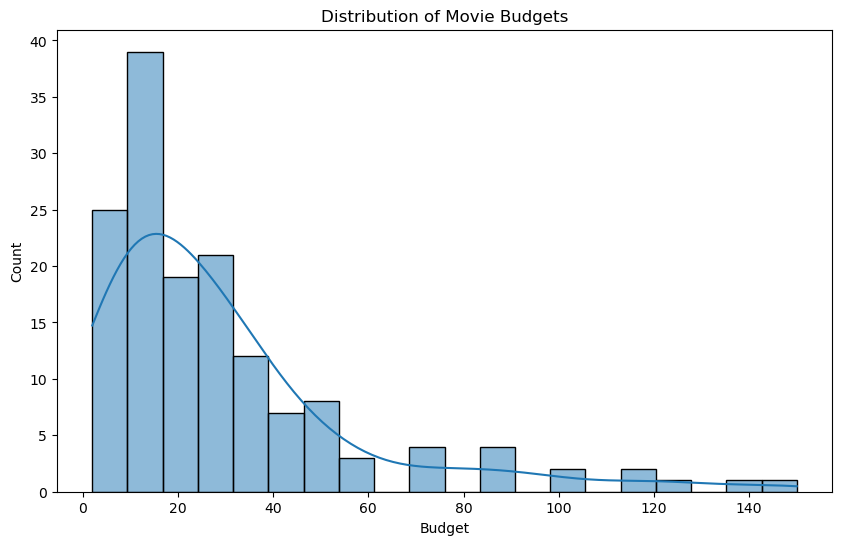

In [18]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10,6))
sns.histplot(reader['Budget'], bins=20, kde=True)
plt.title('Distribution of Movie Budgets')
plt.show()


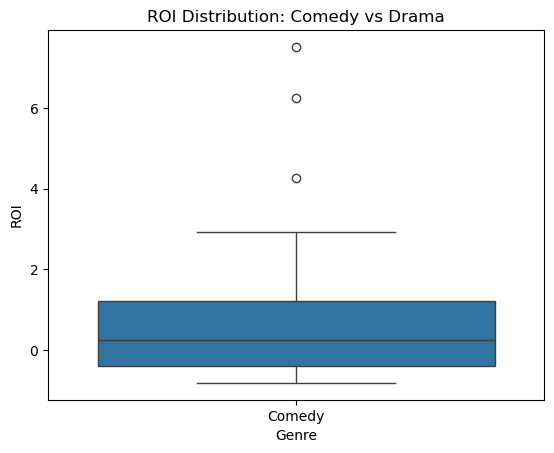

In [19]:
comedy_drama = reader[reader['Genre'].isin(['Comedy', 'Drama'])]
sns.boxplot(x='Genre', y='ROI', data=comedy_drama)
plt.title('ROI Distribution: Comedy vs Drama')
plt.show()


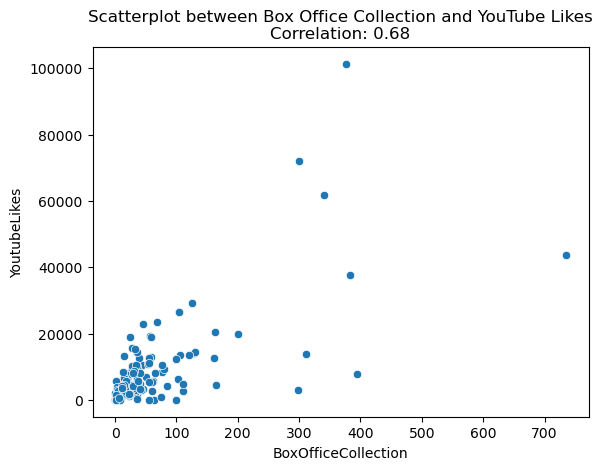

In [20]:
correlation = reader['BoxOfficeCollection'].corr(reader['YoutubeLikes'])
sns.scatterplot(x='BoxOfficeCollection', y='YoutubeLikes', data=reader)
plt.title(f'Scatterplot between Box Office Collection and YouTube Likes\nCorrelation: {correlation:.2f}')
plt.show()


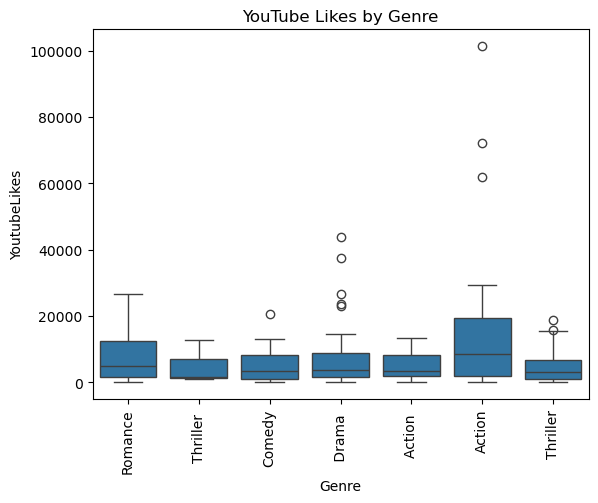

In [21]:
sns.boxplot(x='Genre', y='YoutubeLikes', data=reader)
plt.title('YouTube Likes by Genre')
plt.xticks(rotation=90)
plt.show()


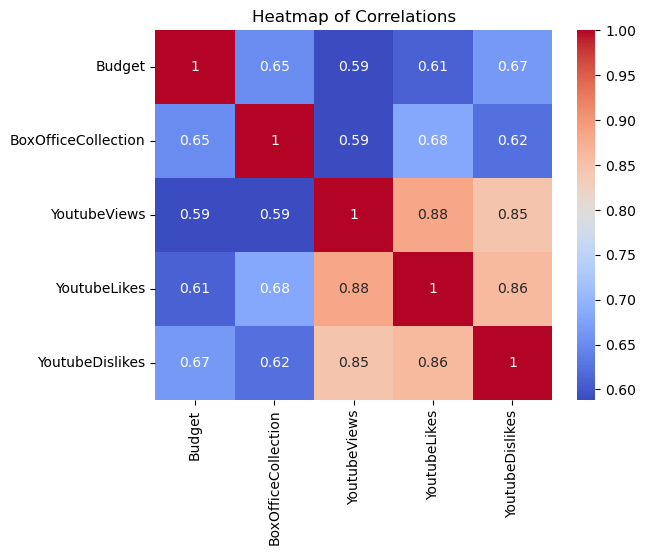

In [22]:
correlation_matrix = reader[['Budget', 'BoxOfficeCollection', 'YoutubeViews', 'YoutubeLikes', 'YoutubeDislikes']].corr()
sns.heatmap(correlation_matrix, annot=True, cmap='coolwarm')
plt.title('Heatmap of Correlations')
plt.show()
